In [1]:
!pip install arch -q

from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

base = "/content/drive/MyDrive/volatility-risk-analysis"
ticker = "GLD"

returns = pd.read_csv(f"{base}/data/{ticker}_returns.csv",
                      index_col=0, parse_dates=True).squeeze("columns")
r = returns * 100
vol_fc = pd.read_csv(f"{base}/data/{ticker}_vol_forecasts.csv",
                     index_col=0, parse_dates=True)

print(returns.shape, vol_fc.shape)
print(vol_fc.head(3))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 10.8 MB/s eta 0:00:00
Mounted at /content/drive
(5481,) (4731, 4)
            GARCH normal   GARCH t  GJR-GARCH t  20-day rolling std
Date                                                               
2007-12-27      1.441052  1.427380     1.453054            1.368149
2007-12-28      1.409996  1.398374     1.430457            1.356772
2007-12-31      1.424427  1.410382     1.472267            1.336893


In [2]:
from arch import arch_model

init, step = 750, 20
model_defs = {
    "GARCH normal": dict(vol="GARCH", p=1, o=0, q=1, dist="normal"),
    "GARCH t":      dict(vol="GARCH", p=1, o=0, q=1, dist="t"),
    "GJR-GARCH t":  dict(vol="GARCH", p=1, o=1, q=1, dist="t"),
}

mu_df = pd.DataFrame(index=vol_fc.index, columns=list(model_defs), dtype=float)
nu_df = pd.DataFrame(index=vol_fc.index, columns=list(model_defs), dtype=float)

starts = list(range(init, len(r), step))
for i, start in enumerate(starts):
    if i % 40 == 0:
        print("refit", i, "of", len(starts))
    end = min(start + step, len(r))
    block = r.index[start:end]
    for name, spec in model_defs.items():
        fit = arch_model(r.iloc[:start], mean="Constant", **spec).fit(disp="off")
        mu_df.loc[block, name] = fit.params["mu"]
        nu_df.loc[block, name] = fit.params.get("nu", np.nan)

mu_df.to_csv(f"{base}/data/{ticker}_mu.csv")
nu_df.to_csv(f"{base}/data/{ticker}_nu.csv")

print(mu_df.describe().round(3))
print(nu_df[["GARCH t", "GJR-GARCH t"]].describe().round(2))
print("missing in mu:", mu_df.isna().sum().sum())

refit 0 of 237
refit 40 of 237
refit 80 of 237
refit 120 of 237
refit 160 of 237
refit 200 of 237
       GARCH normal   GARCH t  GJR-GARCH t
count      4731.000  4731.000     4731.000
mean          0.036     0.060        0.066
std           0.019     0.024        0.025
min           0.014     0.030        0.035
25%           0.021     0.041        0.046
50%           0.026     0.047        0.053
75%           0.054     0.082        0.088
max           0.078     0.111        0.120
       GARCH t  GJR-GARCH t
count  4731.00      4731.00
mean      5.67         5.83
std       0.74         1.02
min       5.04         5.05
25%       5.22         5.24
50%       5.33         5.35
75%       5.87         6.13
max       7.92         9.71
missing in mu: 0


In [3]:
from scipy import stats

test_r = r.loc[vol_fc.index]
n = len(test_r)

def var_threshold(name, alpha):
    sigma = vol_fc[name]
    if name == "20-day rolling std":
        return sigma * stats.norm.ppf(alpha)              # zero mean, normal
    if name == "GARCH normal":
        q = stats.norm.ppf(alpha)
    else:
        nu = nu_df[name]
        q = stats.t.ppf(alpha, nu) * np.sqrt((nu - 2) / nu)
    return mu_df[name] + sigma * q

def kupiec(x, n, p):
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        ph = x / n
        lr = (-2 * ((n - x) * np.log(1 - p) + x * np.log(p))
              + 2 * ((n - x) * np.log(1 - ph) + x * np.log(ph)))
    return lr, 1 - stats.chi2.cdf(lr, 1)

thresholds, rows = {}, []
for alpha in [0.05, 0.01]:
    for name in vol_fc.columns:
        thr = var_threshold(name, alpha)
        thresholds[(name, alpha)] = thr
        x = int((test_r < thr).sum())
        lr, pv = kupiec(x, n, alpha)
        rows.append({
            "confidence": f"{int((1 - alpha) * 100)}%",
            "model": name,
            "avg VaR (%)": (-thr).mean(),
            "breaches": x,
            "expected": alpha * n,
            "breach rate (%)": 100 * x / n,
            "Kupiec p": pv,
            "verdict": "pass" if pv > 0.05 else "FAIL",
        })

result = pd.DataFrame(rows).set_index(["confidence", "model"])
print(result.round(3))

                               avg VaR (%)  breaches  expected  \
confidence model                                                 
95%        GARCH normal              1.778       233    236.55   
           GARCH t                   1.689       267    236.55   
           GJR-GARCH t               1.668       268    236.55   
           20-day rolling std        1.712       294    236.55   
99%        GARCH normal              2.529        78     47.31   
           GARCH t                   2.794        50     47.31   
           GJR-GARCH t               2.754        54     47.31   
           20-day rolling std        2.422       108     47.31   

                               breach rate (%)  Kupiec p verdict  
confidence model                                                  
95%        GARCH normal                  4.925     0.812    pass  
           GARCH t                       5.644     0.046    FAIL  
           GJR-GARCH t                   5.665     0.040    FAIL  
    

99% VaR breaches by period:
                  days  expected  GARCH normal  GARCH t  GJR-GARCH t  \
period                                                                 
2008-2009 crisis   508       5.1             6        5            7   
2010-2013         1006      10.1            22       14           15   
2014-2019 calm    1510      15.1            20        8           12   
2020-2021          505       5.0            13       10            9   
2022-2026         1202      12.0            17       13           11   

                  20-day rolling std  
period                                
2008-2009 crisis                   8  
2010-2013                         28  
2014-2019 calm                    29  
2020-2021                         17  
2022-2026                         26  

Independence of breaches:
                               P(breach | no breach yesterday)  \
confidence model                                                 
95%        GARCH normal            

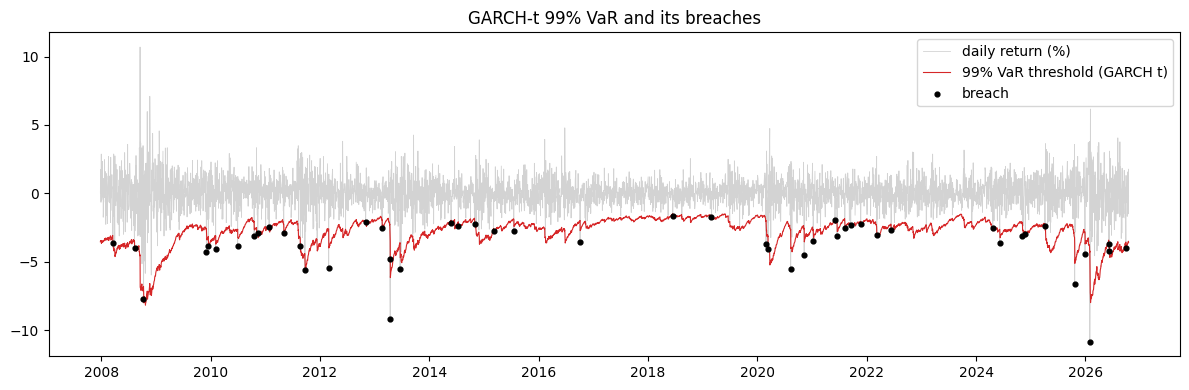

In [4]:
from scipy.special import xlogy

periods = {
    "2008-2009 crisis": ("2007-12-27", "2009-12-31"),
    "2010-2013":        ("2010-01-01", "2013-12-31"),
    "2014-2019 calm":   ("2014-01-01", "2019-12-31"),
    "2020-2021":        ("2020-01-01", "2021-12-31"),
    "2022-2026":        ("2022-01-01", "2026-12-31"),
}

hit = {key: (test_r < thr).astype(int) for key, thr in thresholds.items()}

# 1) 99% breaches by period
rows = []
for label, (a, b) in periods.items():
    d = len(test_r.loc[a:b])
    row = {"period": label, "days": d, "expected": round(0.01 * d, 1)}
    for name in vol_fc.columns:
        row[name] = int(hit[(name, 0.01)].loc[a:b].sum())
    rows.append(row)
print("99% VaR breaches by period:")
print(pd.DataFrame(rows).set_index("period"))

# 2) Christoffersen independence test
def christoffersen_ind(h):
    h = h.values
    n00 = np.sum((h[:-1] == 0) & (h[1:] == 0))
    n01 = np.sum((h[:-1] == 0) & (h[1:] == 1))
    n10 = np.sum((h[:-1] == 1) & (h[1:] == 0))
    n11 = np.sum((h[:-1] == 1) & (h[1:] == 1))
    pi01 = n01 / (n00 + n01)
    pi11 = n11 / (n10 + n11) if (n10 + n11) > 0 else 0.0
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)
    ll0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll1 = (xlogy(n00, 1 - pi01) + xlogy(n01, pi01)
           + xlogy(n10, 1 - pi11) + xlogy(n11, pi11))
    lr = -2 * (ll0 - ll1)
    return pi01, pi11, 1 - stats.chi2.cdf(lr, 1)

ind_rows = []
for (name, alpha), h in hit.items():
    p01, p11, pv = christoffersen_ind(h)
    ind_rows.append({
        "confidence": f"{int((1 - alpha) * 100)}%",
        "model": name,
        "P(breach | no breach yesterday)": p01,
        "P(breach | breach yesterday)": p11,
        "independence p": pv,
    })
print("\nIndependence of breaches:")
print(pd.DataFrame(ind_rows).set_index(["confidence", "model"]).round(3))

# 3) Plot: GARCH t, 99%
thr = thresholds[("GARCH t", 0.01)]
bd = test_r[test_r < thr]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test_r.index, test_r.values, color="lightgray", linewidth=0.6, label="daily return (%)")
ax.plot(thr.index, thr.values, color="tab:red", linewidth=0.8, label="99% VaR threshold (GARCH t)")
ax.scatter(bd.index, bd.values, color="black", s=12, zorder=3, label="breach")
ax.legend()
ax.set_title("GARCH-t 99% VaR and its breaches")
plt.tight_layout()
plt.savefig(f"{base}/outputs/var_breaches_{ticker}.png")
plt.show()

In [6]:
import os

result.to_csv(f"{base}/outputs/var_backtest_summary_{ticker}.csv")
pd.DataFrame(rows).set_index("period").to_csv(f"{base}/outputs/breaches_by_period_{ticker}.csv")
pd.DataFrame(ind_rows).set_index(["confidence", "model"]).to_csv(f"{base}/outputs/independence_{ticker}.csv")
print(os.listdir(f"{base}/outputs"))

['price_vs_returns_^GSPC.png', 'price_vs_returns_GLD.png', 'hist_qq_GLD.png', 'acf_pacf_GLD.png', 'baseline_GLD.png', 'arima_resid_GLD.png', 'garch_vs_baseline_GLD.png', 'garch_resid_GLD.png', 'cumulative_gain_GLD.png', 'var_breaches_GLD.png', 'var_backtest_summary_GLD.csv', 'breaches_by_period_GLD.csv', 'independence_GLD.csv']
